# D010 웹 수집 리포트 — 미술 시장 최고가 그림

**큰 질문: 미술 시장 최고가 그림은 누구의 것이고, 누구에게 팔렸나?**

| 항목 | 내용 |
|---|---|
| 수집 대상 URL | https://en.wikipedia.org/wiki/List_of_most_expensive_paintings |
| robots.txt | https://en.wikipedia.org/robots.txt — 상태 코드 200, 우리 User-Agent로 대상 페이지 `can_fetch` = **True (수집 허용)** |
| 수집 방법 | `requests` + `BeautifulSoup` (정적 페이지) |

| 파트 | 내용 |
|---|---|
| Part 1. 수집 | robots.txt 확인 → 요청·정적 판별 → 표 찾기 → 행 수집 → 검증 → `wiki_paintings_raw.csv` 저장 |
| Part 2. 정제·코딩 | 언어 표시 삭제 → `artist_clean` → 가격·거래 방식·연도 → `artist_gender`, `buyer_type` 코딩 |
| Part 3. 분석 | ① 작가 성별 ② 작가 상위 10명 ③ 구매자 유형 ④ 거래 방식별 가격 |
| Part 4. 보고서 | 개요 / 데이터 수집 / 데이터 설명 / 분석 결과 / 결론 / 한계 |

# Part 1. 데이터 수집

In [1]:
# ① 준비 — 라이브러리와 설정
import time
from urllib.robotparser import RobotFileParser

import pandas as pd
import requests
from bs4 import BeautifulSoup

BASE_URL = "https://en.wikipedia.org"
PAGE_URL = "https://en.wikipedia.org/wiki/List_of_most_expensive_paintings"
HEADERS = {"User-Agent": "student-project/1.0 (edu; web scraping class)"}   # 영어만 (레슨 Part 2)
print("준비 완료")

준비 완료


## ② robots.txt 확인

robots.txt를 requests로 받아서(우리 User-Agent로) 검사 도구에 넣어.
검사 도구가 직접 받게 하면 위키피디아가 기본 이름의 요청을 거절해서 "전부 금지"로 잘못 나올 수 있거든.

In [2]:
# ② robots.txt 확인 — 긁어도 되는 주소인가 (레슨 Part 8)
robots_resp = requests.get(BASE_URL + "/robots.txt", headers=HEADERS, timeout=10)
print("robots.txt 상태 코드:", robots_resp.status_code)

rp = RobotFileParser()
rp.parse(robots_resp.text.splitlines())
print("수집 허용:", rp.can_fetch(HEADERS["User-Agent"], PAGE_URL))

robots.txt 상태 코드: 200
수집 허용: True


In [3]:
# ③ 요청 보내기 + 정적 페이지인지 판별 (레슨 Part 2, Part 3)
time.sleep(1)                                   # robots.txt 요청과 간격 두기 (레슨 Part 8)
resp = requests.get(PAGE_URL, headers=HEADERS, timeout=10)
print("상태 코드:", resp.status_code)           # 200이어야 다음으로
print("본문 길이:", len(resp.text), "글자")

TEST_TITLE = "Salvator Mundi"                   # 표 맨 위 작품
print("화면 작품명이 소스에 있나:", TEST_TITLE in resp.text)

soup = BeautifulSoup(resp.text, "html.parser")
print("페이지 제목:", soup.select_one("title").get_text(strip=True))

상태 코드: 200
본문 길이: 953655 글자
화면 작품명이 소스에 있나: True


페이지 제목: List of most expensive paintings - Wikipedia


## ④ 표 찾기

위키피디아 표는 `class="wikitable"`이야. 이 페이지엔 표가 여러 개라 **몇 번째가 메인 표인지** 확인해.
메인 표 = 첫 열이 조정 가격(Adjusted), 행이 120개 안팎인 표.

In [4]:
# ④ 표 찾기 — wikitable 전부 모아서 각 표의 첫 줄(열 이름)과 행 수 보기
tables = soup.select("table.wikitable")
print("wikitable 개수:", len(tables))
print()
for i in range(len(tables)):
    first_row = tables[i].select_one("tr")
    col_names = [th.get_text(" ", strip=True) for th in first_row.find_all("th")]
    print(i, "번 표 | 행 수:", len(tables[i].select("tr")) - 1, "| 열:", col_names[:4], "…")

wikitable 개수: 2

0 번 표 | 행 수: 127 | 열: ['Adjusted (million USD)', 'Original (million USD)', 'Name', 'Image'] …
1 번 표 | 행 수: 28 | 열: ['Price', 'Painting', 'Image', 'Artist'] …


In [5]:
# ④-2 메인 표 고르기 — 위 출력을 보고 번호가 다르면 바꾸기
TABLE_INDEX = 0
main_table = tables[TABLE_INDEX]

# 각주 [1], 숨은 정렬용 글자처럼 화면 값이 아닌 것 지우기
for tag in main_table.select("sup.reference, sup.noprint, .sortkey, [style*='display:none']"):
    tag.decompose()          # decompose = 그 칸을 HTML에서 없애기

col_names = [th.get_text(" ", strip=True) for th in main_table.select_one("tr").find_all("th")]
print("열 이름", len(col_names), "개:", col_names)

열 이름 11 개: ['Adjusted (million USD)', 'Original (million USD)', 'Name', 'Image', 'Artist', 'Year', 'Date of sale', 'Rank at sale', 'Seller', 'Buyer', 'Auction house']


## ⑤ 행 수집

Part 5에서 **카드**마다 돌았던 것처럼, 여기선 표의 **행(tr)** 마다 돌면서 칸(th, td) 글자를 꺼내.

위키피디아 표는 같은 값이 여러 행에 걸쳐 합쳐진 칸(rowspan)이 있을 수 있어. 그대로 꺼내면 칸이 밀려서 **값이 엉뚱한 열에 들어가**(조용한 실패). 그래서 합쳐진 칸을 행마다 채워 주는 함수를 넣었어. 함수 안은 몰라도 돼 (def, while).

In [6]:
# ⑤ 행 수집 — 합쳐진 칸(rowspan)까지 풀어서 한 행씩 (몰라도 돼: def, while)
def table_to_rows(table, n_cols):
    rows = []
    pending = {}                                   # 열 번호 → [값, 남은 행 수]
    for tr in table.select("tr")[1:]:              # 첫 줄(열 이름)은 빼고
        cells = tr.find_all(["th", "td"], recursive=False)
        row, col, k = [], 0, 0
        while col < n_cols:
            if col in pending:                     # 위에서 내려온 합쳐진 칸
                value, left = pending[col]
                row.append(value)
                if left - 1 > 0:
                    pending[col] = [value, left - 1]
                else:
                    del pending[col]
                col += 1
                continue
            if k >= len(cells):
                break
            cell = cells[k]; k += 1
            text = cell.get_text(" ", strip=True)
            span_down = int(cell.get("rowspan", 1))
            span_side = int(cell.get("colspan", 1))
            for _ in range(span_side):
                row.append(text)
                if span_down > 1:
                    pending[col] = [text, span_down - 1]
                col += 1
        rows.append(row)
    return rows

rows = table_to_rows(main_table, len(col_names))
print("수집한 행 수:", len(rows))
print("칸 수가 열 이름 수와 다른 행:", sum(1 for r in rows if len(r) != len(col_names)), "개")
print()
print("첫 행:", rows[0])

수집한 행 수: 127
칸 수가 열 이름 수와 다른 행: 0 개

첫 행: ['$ 591.5', '$450.3', 'Salvator Mundi', '', 'Leonardo da Vinci (attribution disputed)', 'c. 1500', 'November 15, 2017', '1', 'Dmitry Rybolovlev', 'Badr bin Abdullah Al Saud', "Christie's , New York"]


In [7]:
# ⑥ 표로 만들고 검증 — 조용한 실패 막기
paintings_raw = pd.DataFrame(rows, columns=col_names)

# 이미지 열은 그림 파일이라 빼기 (저작권, 분석에 안 씀)
image_cols = [c for c in paintings_raw.columns if c.lower().startswith("image")]
paintings_raw = paintings_raw.drop(columns=image_cols)

print("모양:", paintings_raw.shape)
print()
print("열별 빈칸 개수:")
print((paintings_raw == "").sum())
paintings_raw.head()

모양: (127, 10)

열별 빈칸 개수:
Adjusted (million USD)     0
Original (million USD)     0
Name                       0
Artist                     0
Year                       0
Date of sale               0
Rank at sale              76
Seller                    16
Buyer                     48
Auction house              0
dtype: int64


,Adjusted (million USD),Original (million USD),Name,Artist,Year,Date of sale,Rank at sale,Seller,Buyer,Auction house
0,$ 591.5,$450.3,Salvator Mundi,Leonardo da Vinci (attribution disputed),c. 1500,"November 15, 2017",1,Dmitry Rybolovlev,Badr bin Abdullah Al Saud,"Christie's , New York"
1,~$ 407,~$300,Interchange,Willem de Kooning,1955,September 2015,1,David Geffen Foundation,Kenneth C. Griffin,Private sale
2,$ 358 +,$250 +,The Card Players,Paul Cézanne,1892/93,April 2011,1,George Embiricos,State of Qatar,Private sale
3,$ 285,$210,Nafea Faa Ipoipo (When Will You Marry?),Paul Gauguin,1892,September 2014,2,Rudolf Staechelin heirs,State of Qatar,Private sale
4,~$ 272,~$200,Number 17A,Jackson Pollock,1948,September 2015,4,David Geffen Foundation,Kenneth C. Griffin,Private sale


In [8]:
# ⑦ 저장 — 엑셀에서 특수문자 안 깨지게 utf-8-sig
paintings_raw.to_csv("wiki_paintings_raw.csv", index=False, encoding="utf-8-sig")
print("저장 완료: wiki_paintings_raw.csv")

저장 완료: wiki_paintings_raw.csv


# Part 2. 정제·코딩

수집한 `wiki_paintings_raw.csv`를 다시 불러와 정제하고, 작가 성별·구매자 유형을 코딩합니다.

## 0. 준비 — 라이브러리와 한글 폰트

In [9]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 그래프 한글 폰트: 맑은 고딕 (Windows 기본 폰트)
plt.rcParams['font.family'] = 'Malgun Gothic'
# 한글 폰트에서 마이너스(-) 기호가 깨지는 것 방지
plt.rcParams['axes.unicode_minus'] = False

# 표가 잘리지 않도록 출력 옵션 조정
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)
pd.set_option('display.width', 200)

## 1. 데이터 불러오기

원본은 그대로 두고(`raw`), 복사본(`df`)에 정제 결과를 새 열로 쌓아 갑니다.

In [10]:
# 원본 CSV 불러오기
raw = pd.read_csv('wiki_paintings_raw.csv')

# 원본은 보존하고 복사본으로 작업
df = raw.copy()

print('행, 열:', df.shape)
df.head()

행, 열: (127, 10)


,Adjusted (million USD),Original (million USD),Name,Artist,Year,Date of sale,Rank at sale,Seller,Buyer,Auction house
0,$ 591.5,$450.3,Salvator Mundi,Leonardo da Vinci (attribution disputed),c. 1500,"November 15, 2017",1.0,Dmitry Rybolovlev,Badr bin Abdullah Al Saud,"Christie's , New York"
1,~$ 407,~$300,Interchange,Willem de Kooning,1955,September 2015,1.0,David Geffen Foundation,Kenneth C. Griffin,Private sale
2,$ 358 +,$250 +,The Card Players,Paul Cézanne,1892/93,April 2011,1.0,George Embiricos,State of Qatar,Private sale
3,$ 285,$210,Nafea Faa Ipoipo (When Will You Marry?),Paul Gauguin,1892,September 2014,2.0,Rudolf Staechelin heirs,State of Qatar,Private sale
4,~$ 272,~$200,Number 17A,Jackson Pollock,1948,September 2015,4.0,David Geffen Foundation,Kenneth C. Griffin,Private sale


In [11]:
# 열별 자료형과 결측치 확인 — 가격·날짜가 모두 문자열이라 그대로는 계산할 수 없음
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 127 entries, 0 to 126
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Adjusted (million USD)  127 non-null    str    
 1   Original (million USD)  127 non-null    str    
 2   Name                    127 non-null    str    
 3   Artist                  127 non-null    str    
 4   Year                    127 non-null    str    
 5   Date of sale            127 non-null    str    
 6   Rank at sale            51 non-null     float64
 7   Seller                  111 non-null    str    
 8   Buyer                   79 non-null     str    
 9   Auction house           127 non-null    str    
dtypes: float64(1), str(9)
memory usage: 10.1 KB


## 2. 정제

### 2-1. 언어 표시 `[ de ]` 지우기 (모든 열)

**기준**: 대괄호 안에 영문 소문자 2~3글자만 있는 `[ de ]`, `[ sv ]`, `[ zh ]` 형태를 삭제하고 앞뒤 공백을 정리합니다.

**이유**: 위키백과에서 "다른 언어판 문서 링크" 표시가 스크래핑할 때 글자로 딸려 들어온 것입니다.
이름의 일부가 아니므로 남겨 두면 `Untitled`와 `Untitled [ de ]`처럼 같은 값이 다르게 집계됩니다.

In [12]:
# 언어 표시 패턴: '[' + 공백(선택) + 영문 소문자 2~3자 + 공백(선택) + ']'
LANG_TAG = r'\s*\[\s*[a-z]{2,3}\s*\]'

changed = []  # (열, 정제 전, 정제 후) 기록
for col in df.columns:
    s = df[col]
    # 문자열 열만 대상 (pandas 버전에 따라 dtype이 object 또는 str)
    if not pd.api.types.is_string_dtype(s):
        continue
    mask = s.str.contains(LANG_TAG, regex=True, na=False)
    for before in s[mask]:
        changed.append((col, before, re.sub(LANG_TAG, '', before).strip()))
    # 실제로 지우기
    df[col] = s.str.replace(LANG_TAG, '', regex=True).str.strip()

print(f'언어 표시 삭제: {len(changed)}건')
pd.DataFrame(changed, columns=['열', '정제 전', '정제 후'])

언어 표시 삭제: 9건


,열,정제 전,정제 후
0,Name,False Start [ de ],False Start
1,Name,Ten Views Of Lingbi Rock [ zh ],Ten Views Of Lingbi Rock
2,Name,Untitled [ de ],Untitled
3,Name,1949-A-No. 1 [ de ],1949-A-No. 1
4,Name,Blossoming Meadow [ de ],Blossoming Meadow
5,Seller,Jacques Koerfer [ de ] heirs,Jacques Koerfer heirs
6,Seller,Fredrik Roos [ sv ],Fredrik Roos
7,Seller,WestSpiel [ de ],WestSpiel
8,Seller,Anna-Maria [ de ] and Stephen Kellen Foundation,Anna-Maria and Stephen Kellen Foundation


### 2-2. 작가명 괄호 떼기 → `artist_clean`

**기준**: `Artist`에서 괄호와 그 안의 내용(예: `(attribution disputed)`)을 지워 `artist_clean`을 만듭니다. 원본 `Artist` 열은 그대로 둡니다.

**이유**: 괄호 안은 "작가 귀속에 이견이 있다"는 **설명**이지 이름이 아닙니다.
그대로 두면 `Leonardo da Vinci`와 `Leonardo da Vinci (attribution disputed)`가 다른 작가로 세어집니다.

In [13]:
# 괄호(와 앞 공백)를 지운 작가명
df['artist_clean'] = df['Artist'].str.replace(r'\s*\(.*?\)', '', regex=True).str.strip()

# 바뀐 행만 확인
df.loc[df['Artist'] != df['artist_clean'], ['Name', 'Artist', 'artist_clean']]

,Name,Artist,artist_clean
0,Salvator Mundi,Leonardo da Vinci (attribution disputed),Leonardo da Vinci


### 2-3. 가격 → `adjusted_musd`, `is_approx`, `is_minimum`

`Adjusted (million USD)`는 **물가를 반영해 현재 가치로 환산한 가격**(백만 달러)입니다.
1987년 거래와 2022년 거래를 같은 기준에서 비교할 수 있어 이후 모든 가격 분석에 이 열을 씁니다.

| 원본 예시 | `adjusted_musd` | 표시 열 |
|---|---|---|
| `$ 591.5` | 591.5 | — |
| `~$ 407` | 407 | `is_approx = True` (추정가) |
| `$ 358 +` | 358 | `is_minimum = True` (최소 금액, 실제는 더 높음) |

**기준**: 문자열에서 **처음 나오는 숫자** 하나만 꺼냅니다. `~`가 있으면 `is_approx`, `+`가 있으면 `is_minimum`을 True로 둡니다.

**이유**: `~`와 `+`는 "정확한 금액이 아니다"라는 정보입니다. 숫자만 남기면 이 사실이 사라지므로 별도 열로 기록해,
결과를 해석할 때 주의하거나 필요하면 정확한 값만 골라 분석할 수 있게 합니다.

In [14]:
ADJ = 'Adjusted (million USD)'

def first_number(text):
    """문자열에서 처음 나오는 숫자 하나를 float으로 반환. 없으면 NaN."""
    if pd.isna(text):
        return np.nan
    m = re.search(r'\d+(?:\.\d+)?', str(text))
    return float(m.group()) if m else np.nan

# 숫자 열
df['adjusted_musd'] = df[ADJ].apply(first_number)

# 특수 기호 표시
df['is_approx'] = df[ADJ].str.contains('~', regex=False)
df['is_minimum'] = df[ADJ].str.contains('+', regex=False)

# 원본이 '$ 숫자' 형태가 아니었던 행만 확인
plain = df[ADJ].str.fullmatch(r'\$ ?\d+(?:\.\d+)?')
df.loc[~plain, ['Name', ADJ, 'adjusted_musd', 'is_approx', 'is_minimum']]

,Name,Adjusted (million USD),adjusted_musd,is_approx,is_minimum
1,Interchange,~$ 407,407.0,True,False
2,The Card Players,$ 358 +,358.0,False,True
4,Number 17A,~$ 272,272.0,True,False
40,Anna's Light,$ 146.1 +,146.1,False,True
81,Darmstadt Madonna,~$ 107,107.0,True,False


### 2-4. 거래 방식 → `sale_type`

**기준**: `Auction house`가 `Private sale`로 시작하면 **개인 거래**, 그 밖은 **경매**.

**이유**: `Private sale`, `Private sale via Christie's`, `Private sale, estimated price`처럼 뒤에 붙는 말이 제각각이지만
모두 "공개 경매가 아닌 거래"라는 점은 같습니다. 경매사가 중개한 경우(`via Christie's`)도 공개 경매에 부쳐진 것이 아니므로 개인 거래로 봅니다.

In [15]:
# 'Private sale'로 시작하면 개인 거래, 아니면 경매
df['sale_type'] = np.where(df['Auction house'].str.startswith('Private sale', na=False), '개인 거래', '경매')

# 원본 표기별로 어떻게 분류됐는지 확인
df.groupby(['sale_type', 'Auction house']).size().rename('건수').to_frame()

건수
sale_type Auction house                                         
개인 거래     Private sale                                        19
          Private sale via Acquavella Galleries Inc., New...   1
          Private sale via Christie's                          1
          Private sale via Christoph Graf Douglas              1
          Private sale via Hervé Aaron                         1
          Private sale via Larry Gagosian                      3
          Private sale via Philippe Ségalot                    1
          Private sale via Richard Gray                        1
          Private sale via Richard Gray.                       1
          Private sale via Sotheby's                           1
          Private sale via Steven Mazoh                        1
          Private sale via Thomas Ammann , Fine Art Zurich     1
          Private sale via Yves Bouvier                        3
          Private sale, estimated price                        1
경매        Beijing Poly Auction                                 3
          Binoche et Godeau Paris                              1
          China Guardian Auctions                              1
          Christie's , New York                                1
          Christie's, London                                   4
          Christie's, New York                                43
          Christie's, New York.                                1
          Christie’s, New York                                 1
          Philips, New York                                    1
          Phillips de Pury & Company                           1
          Sotheby's , New York                                 1
          Sotheby's, Hong Kong                                 1
          Sotheby's, London                                    4
          Sotheby's, New York                                 27
          Sotheby's, New York.                                 1

### 2-5. 거래 연도 → `sale_year`

**기준**: `Date of sale`에서 **4자리 연도**만 꺼냅니다.

**이유**: `November 15, 2017`, `September 2015`, `2013`처럼 형식이 섞여 있어 날짜형으로 한 번에 바꾸면 일부가 실패합니다.
연도는 모든 형식에 들어 있으므로 연도만 꺼내는 것이 단순하고 손실이 없습니다.

In [16]:
# 4자리 연도 추출 → 정수(결측 허용 Int64)
df['sale_year'] = pd.to_numeric(df['Date of sale'].str.extract(r'(\d{4})')[0], errors='coerce').astype('Int64')

# 형식이 서로 다른 예시
df.drop_duplicates(subset='sale_year')[['Date of sale', 'sale_year']].head(6)

,Date of sale,sale_year
0,"November 15, 2017",2017
1,September 2015,2015
2,April 2011,2011
3,September 2014,2014
5,2013,2013
7,"February 1, 2016",2016


### 2-6. 정제 점검 — 숫자로 못 바꾼 값

새로 만든 숫자 열(`adjusted_musd`, `sale_year`)이 비어 있는 행을 출력합니다. 0개면 모두 정상 변환된 것입니다.

In [17]:
num_cols = ['adjusted_musd', 'sale_year']
print(df[num_cols].isna().sum().to_string())

failed = df[df[num_cols].isna().any(axis=1)]
print(f'\n변환 실패 행: {len(failed)}개')
if len(failed):
    display(failed[[ADJ, 'Date of sale'] + num_cols])
else:
    print('→ 모든 값이 숫자로 변환되었습니다.')

adjusted_musd    0
sale_year        0

변환 실패 행: 0개
→ 모든 값이 숫자로 변환되었습니다.


## 3. 코딩

### 3-1. 작가 성별 → `artist_gender`

**기준**: 작가 한 명당 한 번씩 성별을 코딩합니다(남성 / 여성 / 미상).
작품 행마다 코딩하지 않고 **작가 목록 → 사전(dict)** 으로 만든 뒤 `map`으로 붙입니다.
사전에 없는 작가는 자동으로 **미상**이 됩니다.

**이유**: 같은 작가가 여러 행에 나오므로 작가 단위로 한 번만 정하면 일관성이 보장되고, 검토도 작가 수(43명)만큼만 하면 됩니다.
코딩 근거는 각 작가의 널리 알려진 전기 정보입니다.

> **검토 요청**: 아래 표의 `비고`에 '확인 권장'이 붙은 작가는 상대적으로 덜 알려져 있어 직접 확인해 주세요.
> 수정이 필요하면 `GENDER` 사전의 값만 바꾸고 다시 실행하면 됩니다.

In [18]:
# 작가별 성별 코딩 사전 (작가명은 artist_clean 기준)
GENDER = {
    'Amedeo Modigliani': '남성',   'Andy Warhol': '남성',         'Barnett Newman': '남성',
    'Claude Monet': '남성',        'Clyfford Still': '남성',      'Cy Twombly': '남성',
    'David Hockney': '남성',       'Edvard Munch': '남성',        'Edward Hopper': '남성',
    'Fernand Léger': '남성',       'Francis Bacon': '남성',       'Georges Seurat': '남성',
    'Gustav Klimt': '남성',        'Hans Holbein': '남성',        'Henri Matisse': '남성',
    'Jackson Pollock': '남성',     'Jasper Johns': '남성',        'Jean-Michel Basquiat': '남성',
    'Kazimir Malevich': '남성',    'Leonardo da Vinci': '남성',   'Lucian Freud': '남성',
    'Mark Rothko': '남성',         'Pablo Picasso': '남성',       'Paul Cézanne': '남성',
    'Paul Gauguin': '남성',        'Peter Paul Rubens': '남성',   'Pierre-Auguste Renoir': '남성',
    'Pontormo': '남성',            'Qi Baishi': '남성',           'Rembrandt': '남성',
    'René Magritte': '남성',       'Robert Rauschenberg': '남성', 'Roy Lichtenstein': '남성',
    'Sandro Botticelli': '남성',   'Thomas Eakins': '남성',       'Titian': '남성',
    'Vincent van Gogh': '남성',    'Wang Meng': '남성',           'Wang Shaofei': '남성',
    'Willem de Kooning': '남성',   'Wu Bin': '남성',              'Zao Wou-Ki': '남성',
    'Édouard Manet': '남성',
}
# 덜 알려져 있어 사용자가 직접 확인하면 좋은 작가
CHECK = {'Wang Shaofei'}

# 사전에 없는 작가는 '미상'
df['artist_gender'] = df['artist_clean'].map(GENDER).fillna('미상')

In [19]:
# 검토용 표: 작가 이름 / 코딩 결과 / 데이터 속 작품 수 / 비고
gender_review = (df.groupby('artist_clean')
                   .agg(artist_gender=('artist_gender', 'first'), 작품수=('Name', 'size'))
                   .reset_index()
                   .rename(columns={'artist_clean': '작가'}))
gender_review['비고'] = np.where(gender_review['작가'].isin(CHECK), '확인 권장', '')

print(f'작가 {len(gender_review)}명 —', gender_review['artist_gender'].value_counts().to_dict())
gender_review

작가 43명 — {'남성': 43}


,작가,artist_gender,작품수,비고
0,Amedeo Modigliani,남성,4,
1,Andy Warhol,남성,9,
2,Barnett Newman,남성,2,
3,Claude Monet,남성,5,
4,Clyfford Still,남성,1,
5,Cy Twombly,남성,2,
6,David Hockney,남성,1,
7,Edvard Munch,남성,1,
8,Edward Hopper,남성,1,
9,Fernand Léger,남성,1,


### 3-2. 구매자 유형 → `buyer_type`

**기준**: `Buyer` 원문에 아래 키워드 규칙을 **위에서부터 차례로** 적용해 처음 걸린 유형으로 분류합니다.

| 순서 | 유형 | 키워드 |
|---|---|---|
| 0 | 미상 | `Buyer`가 빈칸 |
| 1 | 국가·왕족 | State of, Sheikh, bin, Al Thani, Al Saud |
| 2 | 미술관·공공기관 | Museum, Rijksmuseum, Getty, National Galleries, Louvre |
| 3 | 기업 | Co, Corp, company, Holdings, TV |
| 4 | 익명 | Anonymous, Private collector, Unidentified, collector |
| 5 | 개인 | 위 어디에도 안 걸린 나머지 |

**매칭 방식과 이유**
- **대소문자 무시 + 단어 단위(`\b`) 매칭**: 짧은 키워드를 부분 문자열로 찾으면 오분류가 생깁니다.
  예) `Co` → `Steven A. **Co**hen`이 기업으로, `bin` → `Ro**bin**` 같은 이름이 왕족으로 잡힘.
  단어 경계를 걸면 `Hunan TV & Broadcast Intermediary Co`의 `Co`만 잡힙니다.
- `Al Thani`는 `Al-Thani`처럼 하이픈 표기도 함께 잡도록 공백/하이픈을 모두 허용합니다.
- **순서가 중요**: 한 원문이 여러 유형에 걸릴 수 있으므로 더 구체적인 유형(국가·왕족, 기관)을 먼저 적용합니다.
- `(suspected)`(추정) 표시는 유형 판단에 영향을 주지 않으므로 그대로 둡니다. 예) `The State of Qatar (suspected)` → 국가·왕족.

규칙이 자동 분류이므로 **원문과 결과를 나란히 놓은 검토표**를 아래에 둡니다. 어떤 키워드에 걸렸는지(`matched`)도 함께 보여 줍니다.

In [20]:
# (유형, 키워드 목록) — 위에서부터 차례로 적용
BUYER_RULES = [
    ('국가·왕족',       ['State of', 'Sheikh', 'bin', 'Al[ -]Thani', 'Al Saud']),
    ('미술관·공공기관', ['Museum', 'Rijksmuseum', 'Getty', 'National Galleries', 'Louvre']),
    ('기업',            ['Co', 'Corp', 'company', 'Holdings', 'TV']),
    ('익명',            ['Anonymous', 'Private collector', 'Unidentified', 'collector']),
]

def classify_buyer(text):
    """Buyer 원문 → (유형, 걸린 키워드). 대소문자 무시, 단어 단위 매칭."""
    if pd.isna(text) or str(text).strip() == '':
        return '미상', ''
    for label, keywords in BUYER_RULES:
        for kw in keywords:
            m = re.search(rf'\b{kw}\b', text, flags=re.IGNORECASE)
            if m:
                return label, m.group()
    return '개인', ''

result = df['Buyer'].apply(classify_buyer)
df['buyer_type'] = result.str[0]
df['buyer_matched'] = result.str[1]   # 어떤 키워드에 걸렸는지 (검토용)

In [21]:
# 검토용 표: Buyer 원문(중복 제거) / 분류 결과 / 걸린 키워드 / 등장 횟수
buyer_review = (df.assign(Buyer=df['Buyer'].fillna('(빈칸)'))
                  .groupby(['buyer_type', 'Buyer', 'buyer_matched'])
                  .size().rename('건수').reset_index()
                  .rename(columns={'buyer_matched': 'matched'}))

# 유형 순서대로 정렬
order = ['국가·왕족', '미술관·공공기관', '기업', '익명', '개인', '미상']
buyer_review['buyer_type'] = pd.Categorical(buyer_review['buyer_type'], categories=order, ordered=True)
buyer_review.sort_values(['buyer_type', '건수'], ascending=[True, False]).reset_index(drop=True)

,buyer_type,Buyer,matched,건수
0,국가·왕족,State of Qatar,State of,3
1,국가·왕족,Sheikh Hamad bin Khalifa Al-Thani,Sheikh,2
2,국가·왕족,Badr bin Abdullah Al Saud,bin,1
3,국가·왕족,Hamad bin Jassim bin Jaber Al Thani,bin,1
4,국가·왕족,The State of Qatar (suspected),State of,1
5,미술관·공공기관,Getty Museum,Museum,3
6,미술관·공공기관,National Galleries of Scotland & National Gall...,National Galleries,2
7,미술관·공공기관,Museum of Modern Art New York,Museum,1
8,미술관·공공기관,Philadelphia Museum of Art,Museum,1
9,미술관·공공기관,Rijksmuseum,Rijksmuseum,1


**검토 메모** — 규칙은 지시대로 적용했고, 아래는 규칙상 '개인'으로 분류됐지만 실제로는 다르게 볼 여지가 있는 원문입니다.
바꾸려면 `BUYER_RULES`에 키워드를 추가하고 다시 실행하면 됩니다.

- `Ronald Lauder , Neue Galerie` — 개인(로널드 로더)과 그가 세운 미술관(Neue Galerie)이 함께 적힘. `Galerie`는 키워드에 없음.
- `Mitsukoshi` — 일본 백화점(기업)이지만 키워드에 걸리지 않음.
- `Larry Gagosian` — 개인 이름이지만 갤러리 대표(딜러)로서 구매했을 가능성.
- `Patti Wong , on behalf of a Hong Kong buyer` — 대리인 이름이 적힌 사례로, 실제 구매자는 익명에 가까움.

### 3-3. 정제·코딩 결과 요약

보고서의 "데이터 설명"에 쓰는 숫자를 한 번에 출력합니다.

In [22]:
# 정제·코딩이 끝난 데이터 요약 (보고서용)
print('행, 열:', df.shape)
print('작품 수:', len(df), '| 작가 수:', df['artist_clean'].nunique())
print(f"가격(adjusted_musd): 최소 {df['adjusted_musd'].min()} ~ 최대 {df['adjusted_musd'].max()} 백만 달러")
print(f"가격 평균 {df['adjusted_musd'].mean():.1f} / 중앙값 {df['adjusted_musd'].median():.1f}")
print(f"거래 연도(sale_year): {df['sale_year'].min()} ~ {df['sale_year'].max()}")
print('추정가(~):', df['is_approx'].sum(), '건 | 최소 금액(+):', df['is_minimum'].sum(), '건')
print('구매자(Buyer) 빈칸:', df['Buyer'].isna().sum(), '건')
print()
print('새로 만든 열:', ['artist_clean', 'adjusted_musd', 'is_approx', 'is_minimum',
                      'sale_type', 'sale_year', 'artist_gender', 'buyer_type', 'buyer_matched'])

행, 열: (127, 19)
작품 수: 127 | 작가 수: 43
가격(adjusted_musd): 최소 83.6 ~ 최대 591.5 백만 달러
가격 평균 142.5 / 중앙값 120.5
거래 연도(sale_year): 1987 ~ 2026
추정가(~): 3 건 | 최소 금액(+): 2 건
구매자(Buyer) 빈칸: 48 건

새로 만든 열: ['artist_clean', 'adjusted_musd', 'is_approx', 'is_minimum', 'sale_type', 'sale_year', 'artist_gender', 'buyer_type', 'buyer_matched']


# Part 3. 분석

## 4. EDA

> 가격은 모두 `adjusted_musd`(물가 반영, 백만 달러)를 사용합니다.

### 4-1. 작가 성별별 작품 수와 비율

In [23]:
# 성별별 작품 수와 비율 (데이터에 없는 범주도 0으로 표시)
gender_counts = df['artist_gender'].value_counts().reindex(['남성', '여성', '미상'], fill_value=0)
pd.DataFrame({'작품 수': gender_counts,
              '비율': (gender_counts / gender_counts.sum()).map('{:.1%}'.format)})

,작품 수,비율
artist_gender,,
남성,127,100.0%
여성,0,0.0%
미상,0,0.0%


**해석**: 이 목록의 127점 전부가 남성 작가의 작품이고, 여성 작가 작품은 한 점도 없습니다.
이 데이터에서 가장 싼 작품도 물가 반영 8,000만 달러가 넘으므로(최솟값 83.6), 미술 시장 최상단의 성별 편중이 극단적이라는 것을 보여 줍니다.

### 4-2. 작가별 작품 수 상위 10명

10위에 같은 건수의 작가가 여러 명이면 임의로 자르지 않고 **동점자를 모두** 보여 줍니다(`keep='all'`).
상위 10명 비중은 정확히 10명(`head(10)`) 기준으로 계산합니다.

In [24]:
# 작가별 작품 수
artist_counts = df['artist_clean'].value_counts()

# 상위 10위 (동점자 포함)
top_artists = artist_counts.nlargest(10, keep='all')

# 상위 10명이 전체에서 차지하는 비율
total = len(df)
top10_sum = artist_counts.head(10).sum()
print(f'전체 {total}점, 작가 {artist_counts.size}명')
print(f'상위 10명 작품 수: {top10_sum}점 → 전체의 {top10_sum / total:.1%}')
print(f'(10위 동점자 포함 {len(top_artists)}명 기준: {top_artists.sum()}점 → {top_artists.sum() / total:.1%})')
print(f'1점만 있는 작가: {(artist_counts == 1).sum()}명')

top_artists.rename('작품 수').to_frame()

전체 127점, 작가 43명
상위 10명 작품 수: 77점 → 전체의 60.6%
(10위 동점자 포함 12명 기준: 85점 → 66.9%)
1점만 있는 작가: 22명


,작품 수
artist_clean,
Pablo Picasso,18
Vincent van Gogh,11
Mark Rothko,9
Andy Warhol,9
Gustav Klimt,7
Willem de Kooning,5
Francis Bacon,5
Claude Monet,5
Paul Cézanne,4


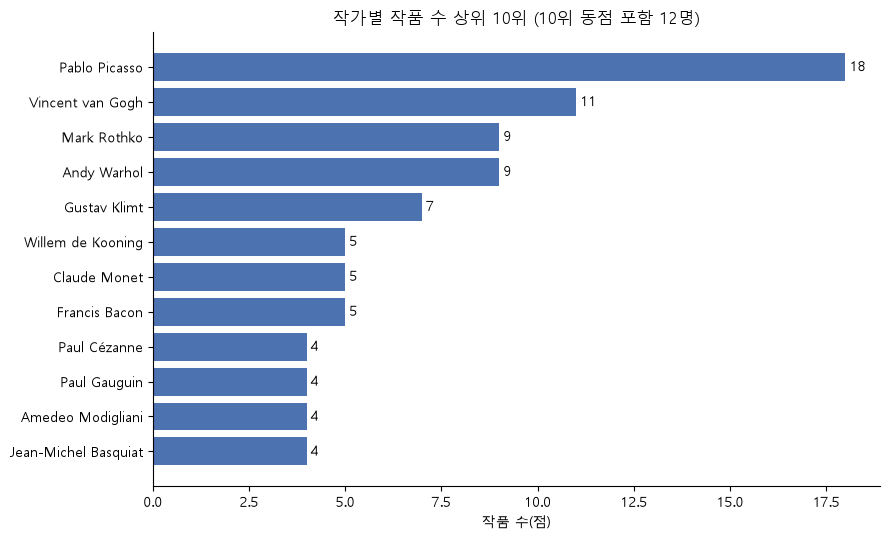

In [25]:
fig, ax = plt.subplots(figsize=(9, 5.5))

# 가로 막대: 많은 작가가 위로 오도록 오름차순 정렬
data = top_artists.sort_values()
bars = ax.barh(data.index, data.values, color='#4C72B0')
ax.bar_label(bars, padding=3)   # 막대 끝에 숫자

ax.set_title(f'작가별 작품 수 상위 10위 (10위 동점 포함 {len(top_artists)}명)')
ax.set_xlabel('작품 수(점)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### 4-3. 구매자 유형별 건수와 비율

In [26]:
# 유형별 건수와 비율 (정해 둔 순서대로, 없는 유형은 0)
bt_counts = df['buyer_type'].value_counts().reindex(order, fill_value=0)
bt_table = pd.DataFrame({'건수': bt_counts,
                         '비율': (bt_counts / bt_counts.sum()).map('{:.1%}'.format)})
bt_table

,건수,비율
buyer_type,,
국가·왕족,8,6.3%
미술관·공공기관,9,7.1%
기업,2,1.6%
익명,10,7.9%
개인,50,39.4%
미상,48,37.8%


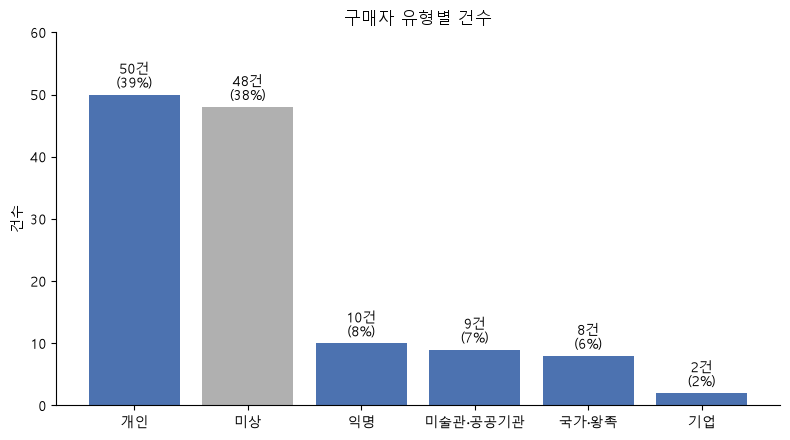

In [27]:
fig, ax = plt.subplots(figsize=(8, 4.5))

# 건수 많은 순으로 정렬해 막대그래프
data = bt_counts.sort_values(ascending=False)
# '미상'(빈칸)은 정보가 없는 범주라 회색으로 구분
colors = ['#B0B0B0' if k == '미상' else '#4C72B0' for k in data.index]
bars = ax.bar(data.index, data.values, color=colors)
ax.bar_label(bars, labels=[f'{v}건\n({v / total:.0%})' for v in data.values], padding=3)

ax.set_title('구매자 유형별 건수')
ax.set_ylabel('건수')
ax.set_ylim(0, data.max() * 1.2)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [28]:
# 참고: 구매자가 알려진 거래만 놓고 본 비율 (미상 제외)
known = bt_counts.drop('미상')
(known / known.sum()).map('{:.1%}'.format).rename('미상 제외 비율').to_frame()

,미상 제외 비율
buyer_type,
국가·왕족,10.1%
미술관·공공기관,11.4%
기업,2.5%
익명,12.7%
개인,63.3%


In [29]:
# 참고: 구매자 유형 × 거래 방식 — '미상'이 어디에 몰려 있나?
pd.crosstab(df['buyer_type'], df['sale_type'], margins=True, margins_name='합계').reindex(order + ['합계'])

sale_type,개인 거래,경매,합계
buyer_type,,,
국가·왕족,4,4,8
미술관·공공기관,7,2,9
기업,0,2,2
익명,2,8,10
개인,22,28,50
미상,1,47,48
합계,36,91,127


In [30]:
# 참고: 구매자 유형별 평균·중앙값 가격
(df.groupby('buyer_type')['adjusted_musd']
   .agg(건수='count', 평균='mean', 중앙값='median')
   .round(1).reindex(order))

,건수,평균,중앙값
buyer_type,,,
국가·왕족,8,246.5,196.6
미술관·공공기관,9,138.9,106.0
기업,2,103.0,103.0
익명,10,119.1,110.0
개인,50,158.4,142.2
미상,48,115.9,104.1


**해석**
- 구매자가 기록된 거래 중에서는 **개인**(리볼로블레프, 스티븐 A. 코언, 켄 그리핀 등)이 약 63%로 가장 많습니다.
- **미상 48건 중 47건이 경매**입니다. 경매에서는 낙찰자를 공개하지 않는 경우가 많기 때문으로, 개인 거래(36건 중 미상 1건)와 대조적입니다.
  따라서 "경매 = 개인 구매자가 적다"가 아니라 "경매는 구매자가 기록되지 않은 경우가 많다"로 읽어야 합니다.
- **국가·왕족**은 8건뿐이지만 평균 가격이 가장 높습니다(살바토르 문디, 카타르 왕실 구매작 등 초고가 거래 포함).
- **미술관·공공기관** 9건 중 7건은 개인 거래입니다(국립미술관끼리 공동 구매, 게티 미술관 등).

### 4-4. 거래 방식별 건수와 평균·중앙값 가격

In [31]:
# 거래 방식별 건수, 평균, 중앙값, 최댓값
by_type = (df.groupby('sale_type')['adjusted_musd']
             .agg(건수='count', 평균='mean', 중앙값='median', 최댓값='max')
             .round(1))
by_type['비율'] = (by_type['건수'] / by_type['건수'].sum()).map('{:.1%}'.format)
by_type

,건수,평균,중앙값,최댓값,비율
sale_type,,,,,
개인 거래,36,177.5,154.9,407.0,28.3%
경매,91,128.7,111.4,591.5,71.7%


In [32]:
# 평균이 극단값에 끌려가는지 확인: 거래 방식별 최고가 3건
for t, g in df.groupby('sale_type'):
    print(f'[{t}] 최고가 3건')
    print(g.nlargest(3, 'adjusted_musd')[['Name', 'artist_clean', 'adjusted_musd', 'is_approx', 'is_minimum']].to_string(index=False), '\n')

[개인 거래] 최고가 3건
                                   Name      artist_clean  adjusted_musd  is_approx  is_minimum
                            Interchange Willem de Kooning          407.0       True       False
                       The Card Players      Paul Cézanne          358.0      False        True
Nafea Faa Ipoipo (When Will You Marry?)      Paul Gauguin          285.0      False       False 

[경매] 최고가 3건
                            Name      artist_clean  adjusted_musd  is_approx  is_minimum
                  Salvator Mundi Leonardo da Vinci          591.5      False       False
Les Femmes d'Alger ("Version O")     Pablo Picasso          243.6      False       False
   Portrait of Elisabeth Lederer      Gustav Klimt          236.4      False       False 



In [33]:
# 참고: 거래 방식별로 추정가(~)·최소금액(+) 행이 몇 건인지
df.groupby('sale_type')[['is_approx', 'is_minimum']].sum()

,is_approx,is_minimum
sale_type,,
개인 거래,3,2
경매,0,0


**해석**
- 개인 거래는 건수로는 약 28%뿐이지만 **평균·중앙값 모두 경매보다 높습니다.** 전체 2~4위(Interchange, The Card Players, Nafea Faa Ipoipo)가 모두 개인 거래입니다.
- 경매 최고가는 1위 *살바토르 문디*(591.5)지만, 이 한 건을 빼면 경매 상위권은 200대 중반에서 멈춥니다.
- 평균과 중앙값을 함께 본 이유: 가격 분포는 초고가 몇 건 때문에 오른쪽 꼬리가 길어, 평균이 끌려 올라갑니다. 중앙값은 그 영향을 덜 받습니다.
- 주의: 추정가(`~`)·최소 금액(`+`) 5건은 모두 개인 거래입니다. 개인 거래 가격은 공식 낙찰가가 아니라 보도된 금액이라 정확도가 낮습니다.

# Part 4. 보고서

## 1. 개요

- **큰 질문**: 미술 시장 최고가 그림은 누구의 것이고, 누구에게 팔렸나?
- **데이터**: 위키백과 *List of most expensive paintings*의 메인 표(127점)
- **방법**: `requests` + `BeautifulSoup`로 표 수집 → 가격·거래 방식·연도 정제 → 작가 성별·구매자 유형 코딩 → 빈도·비율과 평균·중앙값 비교

## 2. 데이터 수집

| 후보 | 결과 | 이유 |
|---|---|---|
| **위키백과 「가장 비싸게 팔린 그림 목록」** | **채택** | 정적 페이지, robots.txt 허용, 작품 127점 |
| Somerset House | 제외 | 행사가 12개뿐이라 분석하기에 데이터가 너무 적음 |
| 국립현대미술관 | 제외 | 동적 페이지라 `requests`로 받은 HTML에는 목록이 없음 |

- **robots.txt**: 상태 코드 200, 대상 페이지 수집 허용(`True`). 요청 사이에는 1초 간격을 두었고, User-Agent에 용도를 밝혔음
- **정적 페이지 확인**: 상태 코드 200, 본문 953,655글자, 화면 맨 위 작품명 `Salvator Mundi`가 소스에 있음 → `requests`로 수집 가능
- **표 찾기**: `wikitable` 2개 중 0번 표(127행, 열 11개)가 메인 표
- **행 수집**: 합쳐진 칸(rowspan)을 풀어서 127행을 수집했고, 칸 수가 열 수와 다른 행은 0개
- **저장**: 이미지 열을 빼고 127행 × 10열을 `wiki_paintings_raw.csv`로 저장

## 3. 데이터 설명

**원본 열(10개)**

| 열 | 내용 | 빈칸 |
|---|---|---|
| Adjusted (million USD) | 물가를 반영한 현재 가치 가격(백만 달러) | 0 |
| Original (million USD) | 거래 당시 가격 | 0 |
| Name / Artist / Year | 작품명 / 작가 / 제작 연도 | 0 |
| Date of sale | 거래 날짜(형식이 섞여 있음) | 0 |
| Rank at sale | 거래 당시 최고가 순위 | 76 |
| Seller / Buyer | 판매자 / 구매자 | 16 / 48 |
| Auction house | 경매사 또는 개인 거래 | 0 |

**새로 만든 열(9개)**: 정제 후 127행 × 19열

| 열 | 내용 |
|---|---|
| `artist_clean` | 괄호 설명을 뗀 작가명(작가 43명) |
| `adjusted_musd` | 숫자로 바꾼 가격: 최소 83.6, 최대 591.5, 평균 142.5, 중앙값 120.5(백만 달러) |
| `is_approx` / `is_minimum` | 추정가(`~`) 3건 / 최소 금액(`+`) 2건 |
| `sale_type` | 경매 91건 / 개인 거래 36건 |
| `sale_year` | 거래 연도 1987~2026, 변환 실패 0건 |
| `artist_gender` | 작가 성별(작가 단위로 직접 코딩) |
| `buyer_type` / `buyer_matched` | 구매자 유형(키워드 규칙) / 걸린 키워드 |

## 4. 분석 결과

### 4-1. 누구의 그림인가? — 작가 성별
- 127점 **전부(100.0%) 남성 작가**의 작품이고, 여성 작가 작품은 0점

### 4-2. 누구의 그림인가? — 작가 집중도
- 작가 43명 중 **상위 10명이 77점(60.6%)**. 10위 동점자까지 넣은 12명 기준으로는 85점(66.9%)
- 1위 Pablo Picasso 18점, 2위 Vincent van Gogh 11점, 공동 3위 Mark Rothko·Andy Warhol 9점
- 1점만 있는 작가가 22명 → 소수 작가에게 몰리고 긴 꼬리가 붙은 구조

### 4-3. 누구에게 팔렸나? — 구매자 유형

| 유형 | 건수 | 전체 비율 | 미상 제외 비율 | 평균가 | 중앙값 |
|---|---|---|---|---|---|
| 개인 | 50 | 39.4% | 63.3% | 158.4 | 142.2 |
| 익명 | 10 | 7.9% | 12.7% | 119.1 | 110.0 |
| 미술관·공공기관 | 9 | 7.1% | 11.4% | 138.9 | 106.0 |
| 국가·왕족 | 8 | 6.3% | 10.1% | 246.5 | 196.6 |
| 기업 | 2 | 1.6% | 2.5% | 103.0 | 103.0 |
| 미상 | 48 | 37.8% | — | 115.9 | 104.1 |

- 구매자가 알려진 거래에서는 **개인이 63.3%**로 가장 많음
- **국가·왕족**은 8건뿐이지만 평균가(246.5)와 중앙값(196.6)이 가장 높음
- **미상 48건 중 47건이 경매** → 경매는 낙찰자를 공개하지 않는 경우가 많음

### 4-4. 어떻게 거래됐나? — 거래 방식

| 거래 방식 | 건수 | 비율 | 평균 | 중앙값 | 최댓값 |
|---|---|---|---|---|---|
| 경매 | 91 | 71.7% | 128.7 | 111.4 | 591.5 |
| 개인 거래 | 36 | 28.3% | 177.5 | 154.9 | 407.0 |

- 건수는 경매가 많지만, **평균·중앙값은 개인 거래가 더 높음**
- 경매 최고가는 *Salvator Mundi*(591.5). 그다음 경매 최고가는 *Les Femmes d'Alger ("Version O")* 243.6
- 추정가·최소 금액 5건(3 + 2)은 모두 개인 거래

## 5. 결론

## 5. 결론

**큰 질문: 미술 시장 최고가 그림은 누구의 것이고, 누구에게 팔렸나?**

1. **최고가 그림은 모두 남성 작가의 작품이었다.**
   물가 반영 가격 8,360만~5억 9,150만 달러에 거래된 127점 중 여성 작가 작품은 0점이다.
   → 미술 시장의 최상위 가격대는 남성 작가가 독점하고 있다.

2. **소수 작가에게 쏠려 있다.**
   피카소 혼자 18점(14%)이고, 상위 작가 [확인: 공동 10위까지 12명]의 작품이 전체의 60.6%를 차지한다.
   → 최고가 시장은 "누구의 작품인가"가 가격을 크게 좌우하는, 소수 유명 작가 중심 구조다.

3. **구매자가 공개된 거래는 대부분 개인이 샀다.**
   구매자가 공개된 79건 중 개인 50건(63%), 익명 10건(13%), 미술관·공공기관 9건(11%), 국가·왕족 8건(10%), 기업 2건(3%)이다.
   국가·왕족 8건 중 다수가 카타르 정부와 왕족이다.
   → 최고가 그림의 대부분은 공공 미술관이 아니라 개인 소장으로 들어갔다.

4. **개인 거래가 경매보다 비싸게 나타났지만, 그대로 믿기는 어렵다.**
   개인 거래 36건의 중앙값은 1억 5,490만 달러로 경매 91건(1억 1,140만 달러)보다 높다.
   그러나 개인 거래 가격에는 추정치("~", "estimated")가 [확인: ○건 중 ○건] 섞여 있다.
   → 개인 거래는 가격이 공개되지 않아 정확한 비교가 어렵다는 것 자체가 시장의 불투명성을 보여준다.

**종합:** 미술 시장 최고가 그림은 소수의 남성 유명 작가가 만들고, 대부분 개인 부호에게 팔렸다.
가격의 정점에서 성별 불평등과 소수 집중이 동시에 나타난다.

## 6. 한계

- **표본 범위**: 위키백과 목록은 공개된 거래만 담고 있어, 알려지지 않은 개인 거래는 빠져 있을 수 있음
- **구매자 미상**: 구매자 빈칸이 48건(37.8%)이고 그중 47건이 경매라서, 구매자 유형 비율은 "구매자가 공개된 거래" 기준으로 읽어야 함
- **가격 정확도**: 추정가 3건과 최소 금액 2건은 정확한 금액이 아님(모두 개인 거래)
- **코딩의 주관성**: `artist_gender`는 전기 정보로 직접 코딩한 값이고, `buyer_type`은 키워드 규칙으로 자동 분류한 값. 예를 들어 `Mitsukoshi`(백화점)나 `Ronald Lauder , Neue Galerie`는 규칙상 '개인'으로 분류됨
- **시점**: 실행할 때마다 위키백과 최신 문서를 가져오므로, 문서가 고쳐지면 숫자가 달라질 수 있음